In [22]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

root = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / 'cases').is_dir())
sys.path[:0] = [str(root), str(root / 'src')]
from cases import plane_wave, lg_00, lg_01, lg_02
from optomechanics_levitation import parameters as p


In [23]:
def plot_fields(case, name):
    pupil_radius = p.FOCAL_DISTANCE_NM * p.NUMERICAL_APERTURE / p.REFRACTIVE_INDEX
    pupil_axis = np.linspace(-pupil_radius, pupil_radius, 101)
    x, y = np.meshgrid(pupil_axis, pupil_axis)
    pupil_points = np.stack((x, y, np.zeros_like(x)), axis=-1)
    pupil = case.beam.evaluate('field', position=pupil_points, polarization=p.INCIDENT_POLARIZATION)
    pupil[np.hypot(x, y) > pupil_radius] = np.nan

    focus_halfwidth = 2 * p.WAVELENGTH_NM * p.FOCAL_DISTANCE_NM / (np.pi * p.ENTRANCE_WAIST_NM)
    focus_axis = np.linspace(-focus_halfwidth, focus_halfwidth, 81)
    x, y = np.meshgrid(focus_axis, focus_axis)
    focus_points = np.stack((x, y, np.zeros_like(x)), axis=-1)
    focus = case.field(focus_points)

    fig, axes = plt.subplots(2, 4, figsize=(16, 8), constrained_layout=True)
    for row, (field, axis, plane) in enumerate(((pupil, pupil_axis, 'Pupil'), (focus, focus_axis, 'Focus'))):
        maps = (np.linalg.norm(field, axis=-1), *(np.abs(field[..., i]) for i in range(3)))
        scale = np.nanmax(maps[0])
        for col, (values, component) in enumerate(zip(maps, ('|E|', '|Ex|', '|Ey|', '|Ez|'))):
            ax = axes[row, col]
            extent = (axis[0] / 1000, axis[-1] / 1000, axis[0] / 1000, axis[-1] / 1000)
            image = ax.imshow(values, origin='lower', extent=extent, cmap='magma', vmin=0, vmax=scale)
            ax.set_title(f'{plane}: {component}')
            ax.set_xlabel('x (µm)')
            ax.set_ylabel('y (µm)')
        fig.colorbar(image, ax=axes[row, :], orientation='horizontal', location='bottom', label='V/m')
    fig.suptitle(name)
    plt.show()

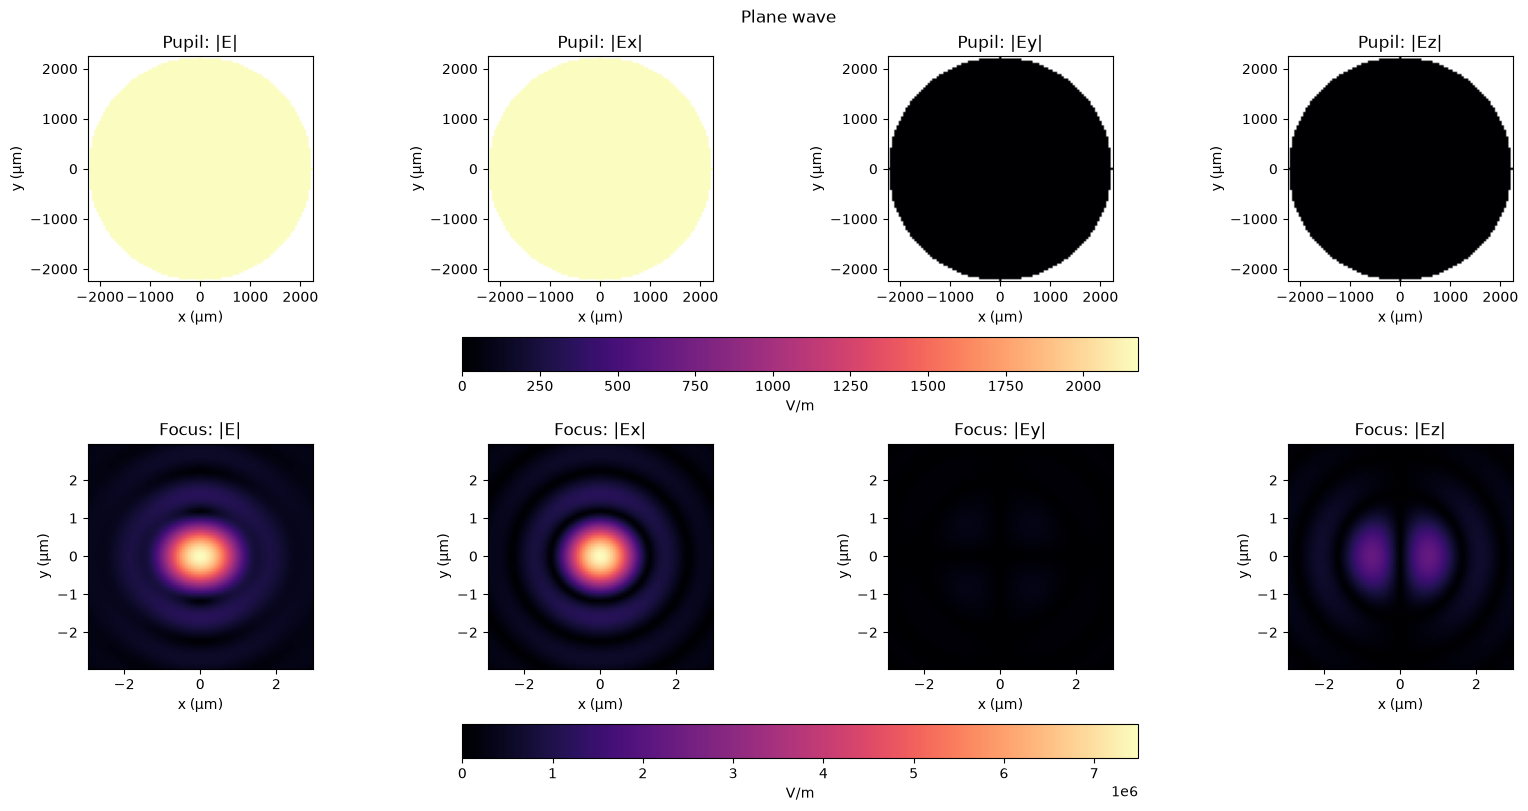

In [24]:
plot_fields(plane_wave, 'Plane wave')

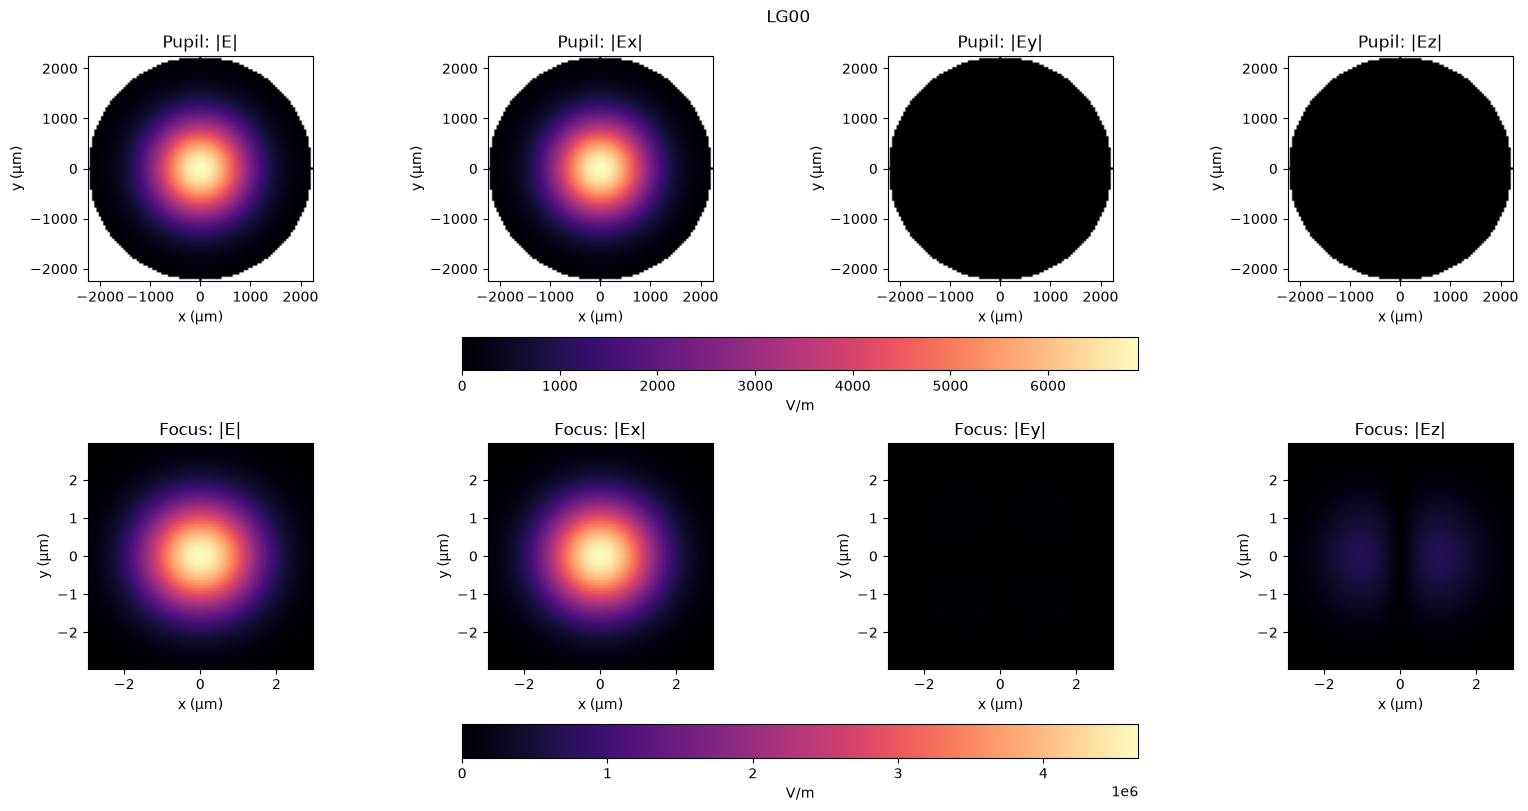

In [25]:
plot_fields(lg_00, 'LG00')

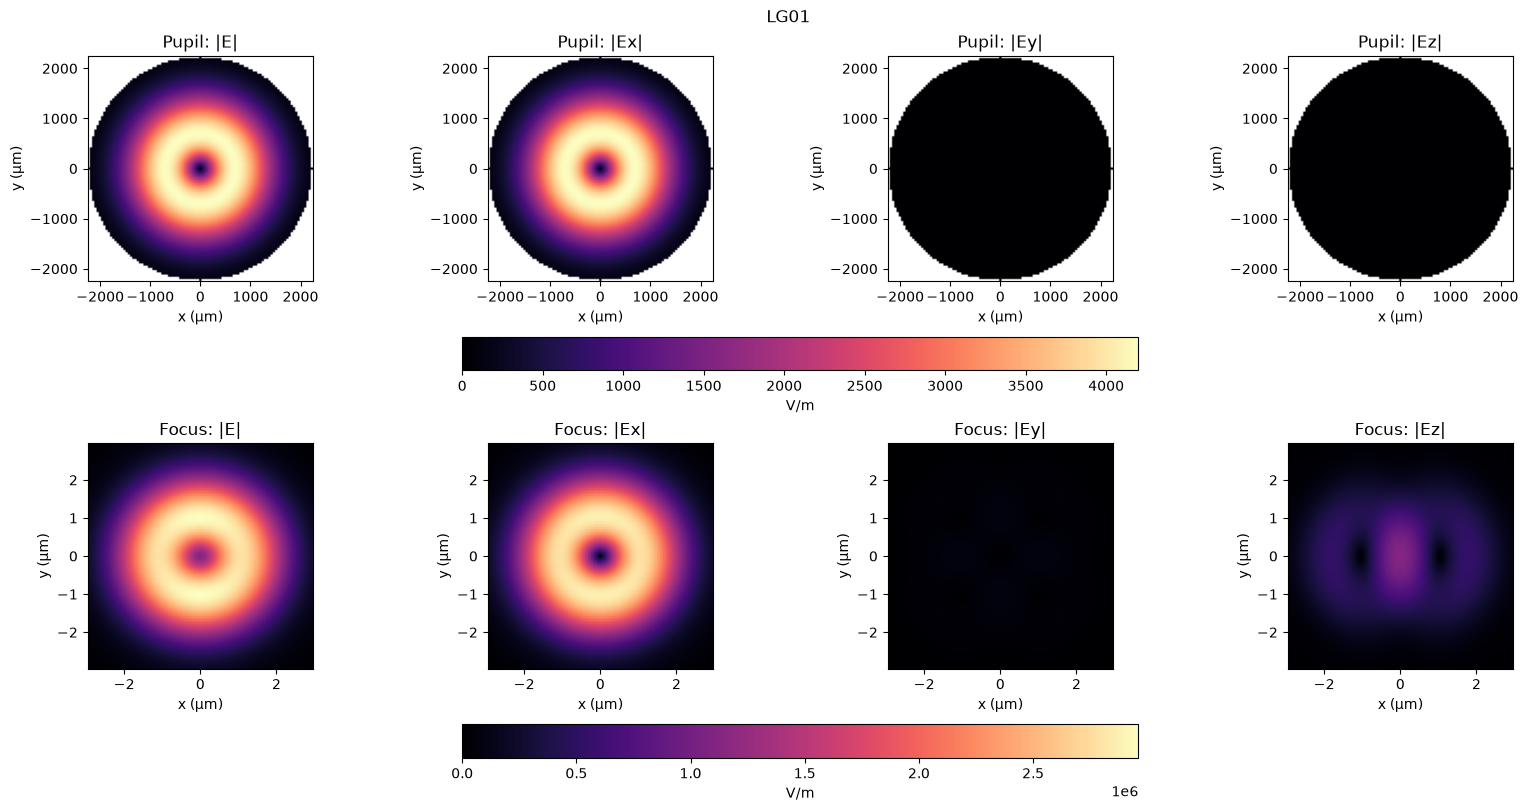

In [26]:
plot_fields(lg_01, 'LG01')

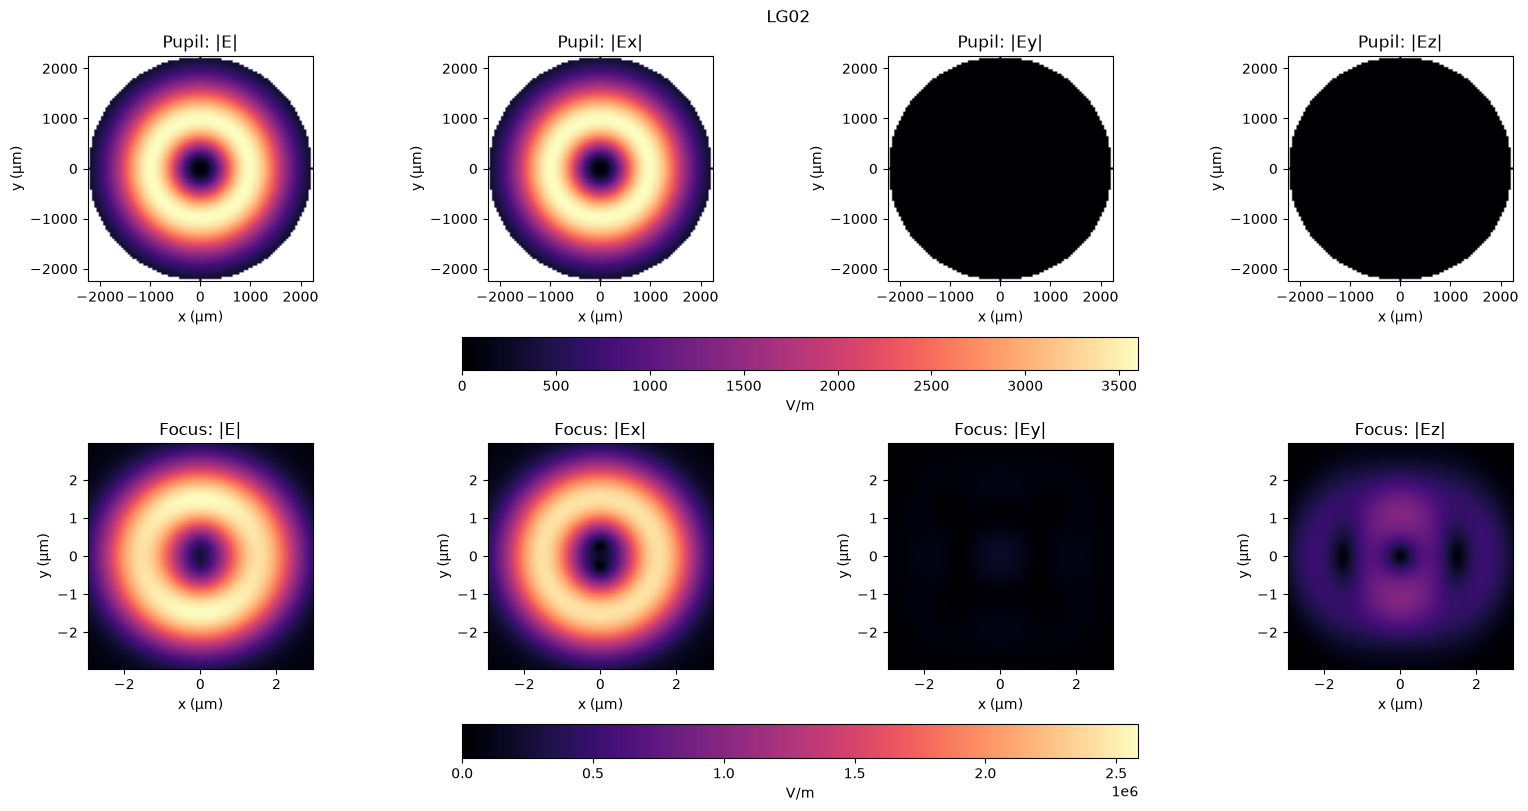

In [27]:
plot_fields(lg_02, 'LG02')

## Field at the center and rotation axes
The first figure shows the direction of E during one optical cycle at the particle center. Each beam is normalized by its own central field to compare directions. The second figure zooms in on the focus center: C_z and C_y indicate the field that couples to each rotation in the dipole approximation, not the full recoil.


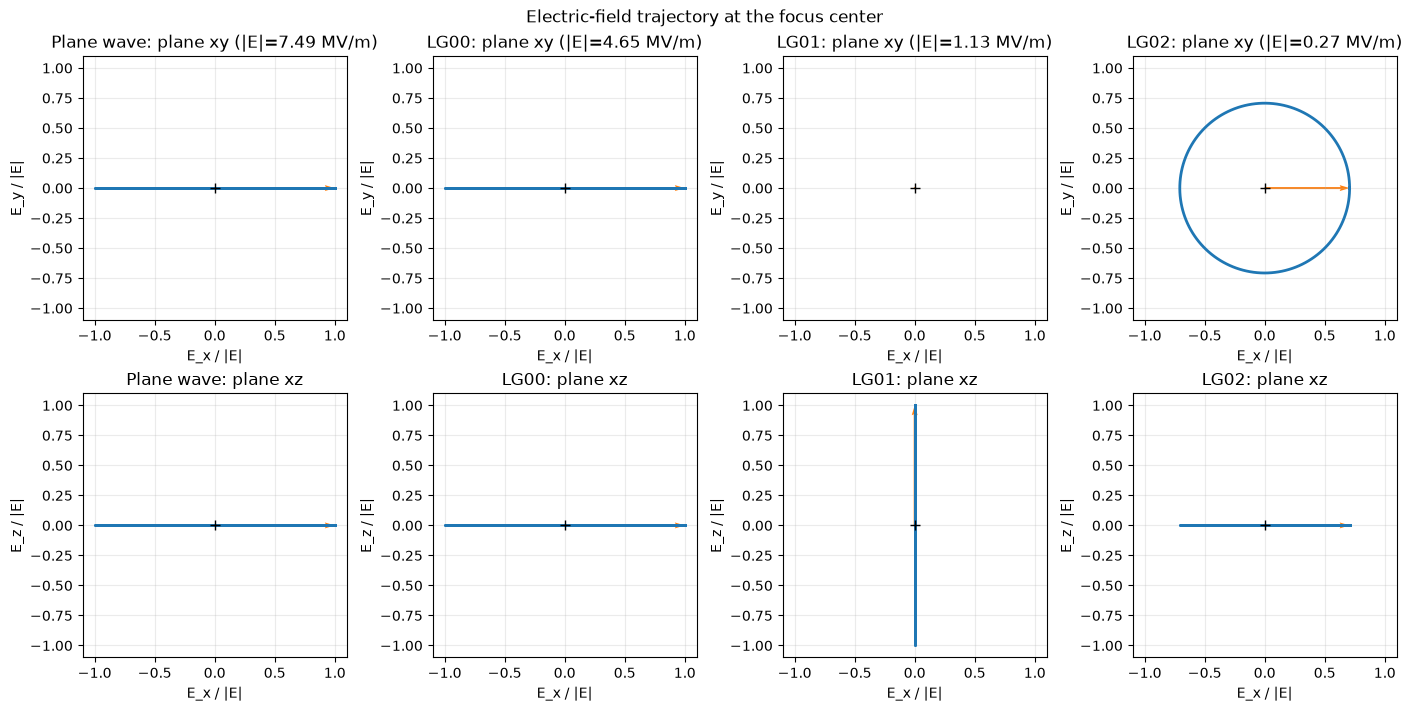

In [28]:
beams = [('Plane wave', plane_wave), ('LG00', lg_00), ('LG01', lg_01), ('LG02', lg_02)]
phase = np.linspace(0, 2 * np.pi, 300)
fig, axes = plt.subplots(2, 4, figsize=(14, 7), constrained_layout=True)

for col, (name, case) in enumerate(beams):
    field = case.field(np.zeros((1, 3)))[0]
    amplitude = np.linalg.norm(field)
    field = field * np.exp(-1j * np.angle(field[np.argmax(np.abs(field))])) / amplitude
    trajectory = np.real(np.exp(-1j * phase[:, None]) * field[None, :])

    for row, (i, j, plane) in enumerate(((0, 1, 'xy'), (0, 2, 'xz'))):
        ax = axes[row, col]
        ax.plot(trajectory[:, i], trajectory[:, j], color='tab:blue', lw=2)
        ax.quiver(0, 0, trajectory[0, i], trajectory[0, j],
                  angles='xy', scale_units='xy', scale=1, color='tab:orange')
        ax.plot(0, 0, 'k+', ms=7)
        ax.set(xlim=(-1.1, 1.1), ylim=(-1.1, 1.1),
               xlabel=f'E_{"xyz"[i]} / |E|', ylabel=f'E_{"xyz"[j]} / |E|')
        ax.set_aspect('equal')
        ax.grid(alpha=0.25)
        ax.set_title(f'{name}: plane {plane}' + (f' (|E|={amplitude/1e6:.2f} MV/m)' if row == 0 else ''))

fig.suptitle('Electric-field trajectory at the focus center')
plt.show()


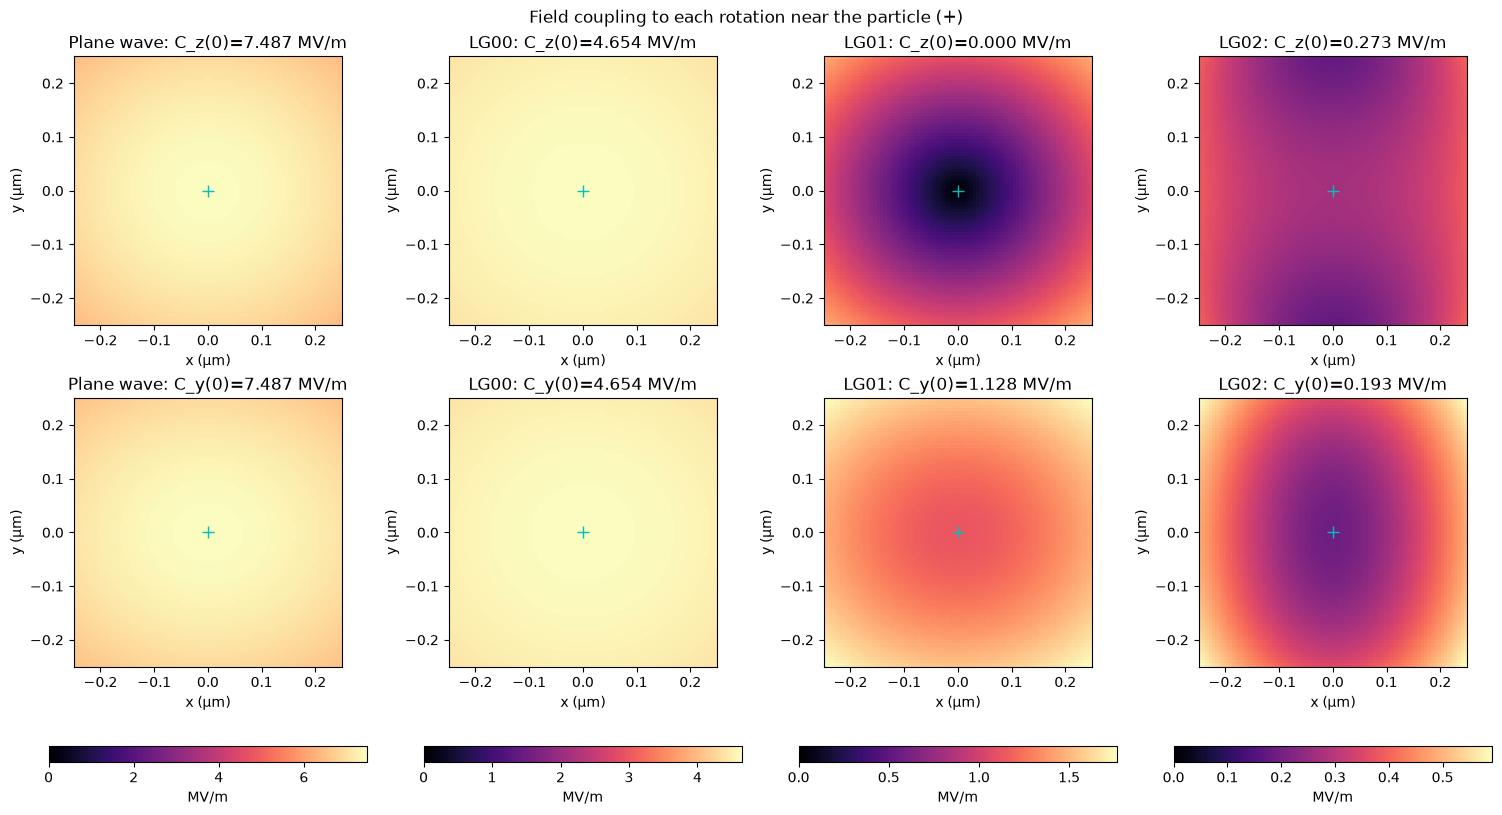

In [29]:
axis_nm = np.linspace(-250, 250, 81)
x, y = np.meshgrid(axis_nm, axis_nm)
points = np.stack((x, y, np.zeros_like(x)), axis=-1)
fig, axes = plt.subplots(2, 4, figsize=(15, 8), constrained_layout=True)

for col, (name, case) in enumerate(beams):
    field = case.field(points)
    coupling_z = np.hypot(np.abs(field[..., 0]), np.abs(field[..., 1]))
    coupling_y = np.hypot(np.abs(field[..., 0]), np.abs(field[..., 2]))
    scale = max(coupling_z.max(), coupling_y.max()) / 1e6

    for row, (values, torque_axis) in enumerate(((coupling_z, 'z'), (coupling_y, 'y'))):
        ax = axes[row, col]
        image = ax.imshow(values / 1e6, origin='lower', extent=(-0.25, 0.25, -0.25, 0.25),
                          cmap='magma', vmin=0, vmax=scale)
        ax.plot(0, 0, 'c+', ms=8, mew=1)
        ax.set_title(f'{name}: C_{torque_axis}(0)={values[40, 40]/1e6:.3f} MV/m')
        ax.set_xlabel('x (µm)')
        ax.set_ylabel('y (µm)')

    fig.colorbar(image, ax=axes[:, col], orientation='horizontal', label='MV/m')

fig.suptitle('Field coupling to each rotation near the particle (+)')
plt.show()
